# Plant Disease Detection Using Convolutional Neural Networks (CNNs) in Google Colab

This notebook implements a complete, self-contained deep learning pipeline to detect plant diseases from leaf images using a Convolutional Neural Network (CNN) built from scratch using TensorFlow/Keras.

### Project Workflow:
1. **Environment Setup**: Checking hardware, library versions, and configuring reproducibility.
2. **Dataset Acquisition & Inspection**: Fetching the PlantVillage dataset, focusing on tomato classes, and visualizing sample images.
3. **Data Splitting & Augmentation**: Splitting the dataset into Training (70%), Validation (15%), and Test (15%) splits with proper preprocessing.
4. **Model Architecture**: Designing and compiling a deep CNN from scratch.
5. **Model Training**: Running the training loop with early stopping and model checkpointing.
6. **Model Evaluation**: Plotting learning curves, evaluating on test data, printing classification reports, and plotting a confusion matrix.
7. **Predict on Custom Images**: Interface to upload and classify local leaf images.
8. **Export and Deliverables**: Saving the model, training history, and exporting deliverables in a single ZIP file.

## 1. Imports and Environment Verification

We verify our Python version, TensorFlow version, and check if a GPU runtime is available to accelerate CNN training.

In [1]:
import os
import sys
import json
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# Set random seeds for reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Python Version: {sys.version}")
print(f"TensorFlow Version: {tf.__version__}")

# Check GPU Availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU is available: {gpus}")
    # Display detailed GPU information
    !nvidia-smi
else:
    print("GPU is NOT available. Running on CPU runtime.")

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow Version: 2.21.0
GPU is available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Thu Oct 29 16:09:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       3Mi

## 2. Dataset Acquisition & Inspection

We will download the `plant_village` dataset using TensorFlow Datasets (`tfds`). We will then filter, extract, and convert the dataset into a standard directory layout focusing on our target tomato categories:
- Tomato healthy
- Tomato early blight
- Tomato late blight
- Tomato leaf mold

In [2]:
!pip install -q importlib-resources
import tensorflow_datasets as tfds

print("Downloading PlantVillage dataset via TFDS...")
ds_raw, info = tfds.load('plant_village', with_info=True, as_supervised=True)
print("Dataset downloaded successfully.")

# Inspect available classes
all_classes = info.features['label'].names
print(f"Total classes in PlantVillage: {len(all_classes)}")
print("First 10 classes:", all_classes[:10])

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset downloaded successfully.
Total classes in PlantVillage: 38
First 10 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy']


In [3]:
# Map our target Tomato classes using flexible, case-insensitive substring matching
target_substrings = {
    'Tomato_healthy': 'tomato___healthy',
    'Tomato_early_blight': 'tomato___early_blight',
    'Tomato_late_blight': 'tomato___late_blight',
    'Tomato_leaf_mold': 'tomato___leaf_mold'
}

target_mapping = {}
for custom_name, sub in target_substrings.items():
    matched = False
    for idx, name in enumerate(all_classes):
        if sub.lower() == name.lower() or name.lower().replace(' ', '_') == sub.lower():
            target_mapping[idx] = custom_name
            matched = True
            break
    # Fallback to loose substring matching if exact match not found
    if not matched:
        for idx, name in enumerate(all_classes):
            if 'tomato' in name.lower() and custom_name.split('_')[-1].lower() in name.lower():
                target_mapping[idx] = custom_name
                break

print("Detected Target Class Mapping:", target_mapping)

Detected Target Class Mapping: {30: 'Tomato_healthy', 29: 'Tomato_early_blight', 31: 'Tomato_late_blight', 32: 'Tomato_leaf_mold'}


In [4]:
# Extract images to local structured directories to perform standard train/val/test splits
base_dataset_dir = '/content/tomato_dataset'
os.makedirs(base_dataset_dir, exist_ok=True)
for class_name in target_mapping.values():
    os.makedirs(os.path.join(base_dataset_dir, class_name), exist_ok=True)

print("Extracting target classes into structured folders...")
count = 0
all_splits = list(ds_raw.keys())
for split_name in all_splits:
    for image_tensor, label_tensor in ds_raw[split_name]:
        label_idx = int(label_tensor.numpy())
        if label_idx in target_mapping:
            class_name = target_mapping[label_idx]
            img_array = image_tensor.numpy()
            # Save image using PIL
            img = Image.fromarray(img_array)
            img.save(os.path.join(base_dataset_dir, class_name, f"img_{count}.jpg"))
            count += 1

print(f"Extraction complete. Total target images saved: {count}")

Extracting target classes into structured folders...
Extraction complete. Total target images saved: 5451


In [5]:
# Inspect the extracted local dataset distribution
class_distribution = {}
for class_name in target_mapping.values():
    class_path = os.path.join(base_dataset_dir, class_name)
    num_images = len(os.listdir(class_path))
    class_distribution[class_name] = num_images
    print(f"{class_name}: {num_images} images")

Tomato_healthy: 1591 images
Tomato_early_blight: 1000 images
Tomato_late_blight: 1908 images
Tomato_leaf_mold: 952 images


## 3. Dataset Inspection and Sample Visualization

Let's plot the class distribution and display representative sample images from each of our four target tomato classes.

/tmp/ipykernel_561/2166631549.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_distribution.keys()), y=list(class_distribution.values()), palette='viridis')


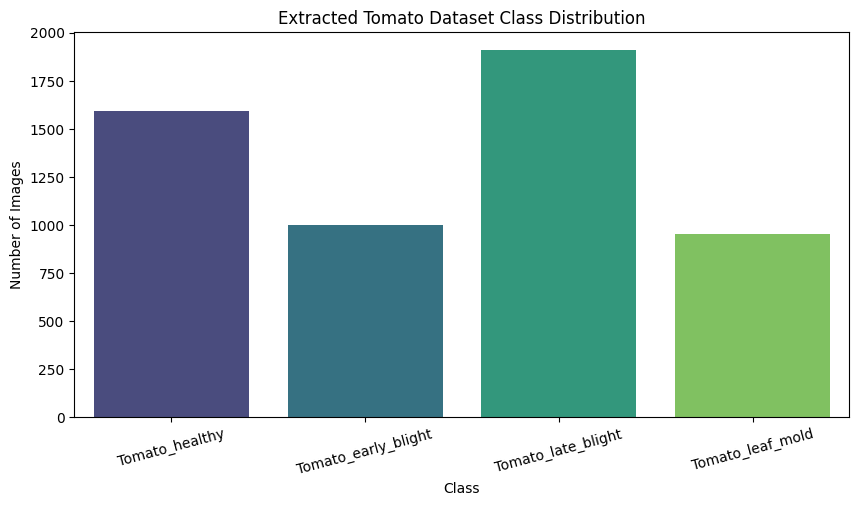

In [6]:
# 1. Run the local distribution inspection
class_distribution = {}
for class_name in target_mapping.values():
    class_path = os.path.join(base_dataset_dir, class_name)
    num_images = len(os.listdir(class_path))
    class_distribution[class_name] = num_images

# 2. Plot the distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_distribution.keys()), y=list(class_distribution.values()), palette='viridis')
plt.title("Extracted Tomato Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()

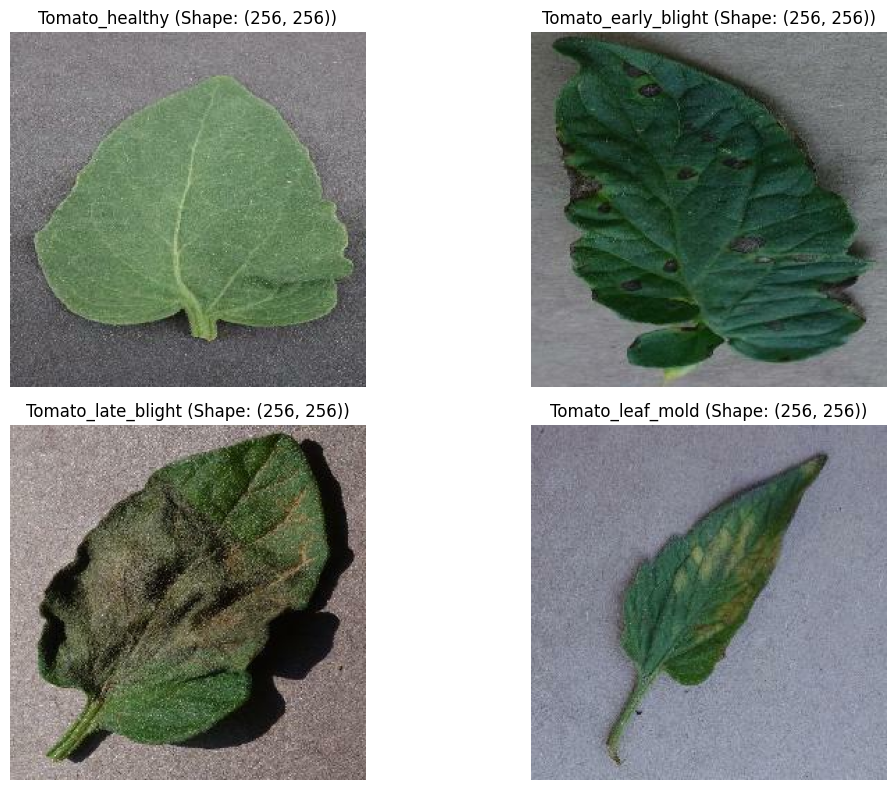

In [7]:
# Visualize some samples dynamically
plt.figure(figsize=(12, 8))
for idx, class_name in enumerate(class_distribution.keys()):
    class_path = os.path.join(base_dataset_dir, class_name)
    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)

    img = Image.open(img_path)
    plt.subplot(2, 2, idx + 1)
    plt.imshow(img)
    plt.title(f"{class_name} (Shape: {img.size})")
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Train, Validation, and Test Splitting

We dynamically structure the extracted files into Train (70%), Validation (15%), and Test (15%) directories to prepare them for loading. This division ensures stratified allocations of all four tomato categories.

In [8]:
split_dirs = {
    'train': '/content/dataset_splits/train',
    'val': '/content/dataset_splits/val',
    'test': '/content/dataset_splits/test'
}

# Clear clean-up to make the script completely re-runnable
if os.path.exists('/content/dataset_splits'):
    shutil.rmtree('/content/dataset_splits')

for split_name, split_path in split_dirs.items():
    for class_name in class_distribution.keys():
        os.makedirs(os.path.join(split_path, class_name), exist_ok=True)

# Copy files according to stratified split ratios
for class_name in class_distribution.keys():
    class_path = os.path.join(base_dataset_dir, class_name)
    all_imgs = sorted(os.listdir(class_path))
    random.seed(SEED)
    random.shuffle(all_imgs)

    total_imgs = len(all_imgs)
    train_idx = int(total_imgs * 0.70)
    val_idx = int(total_imgs * 0.85)

    splits = {
        'train': all_imgs[:train_idx],
        'val': all_imgs[train_idx:val_idx],
        'test': all_imgs[val_idx:]
    }

    for split_name, files in splits.items():
        for f in files:
            src = os.path.join(class_path, f)
            dst = os.path.join(split_dirs[split_name], class_name, f)
            shutil.copy(src, dst)

print("Train/Val/Test directories ready!")

Train/Val/Test directories ready!


## 5. Image Preprocessing and Augmentation

We resize the images to 128x128 pixels, normalize pixel values to `[0, 1]`, and configure moderate augmentation transformations (such as flipping, zooming, and shifting) only for our training subset.

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Moderate data augmentation only on training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# No augmentation on Validation and Testing splits (only normalization)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    split_dirs['train'],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    seed=SEED
)

val_generator = val_test_datagen.flow_from_directory(
    split_dirs['val'],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    seed=SEED,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    split_dirs['test'],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    seed=SEED,
    shuffle=False
)

# Export the class to index mapping to keep it persistent
class_indices = train_generator.class_indices
with open('class_indices.json', 'w') as f:
    json.dump(class_indices, f)
print("Class Indices Saved:", class_indices)

Found 3814 images belonging to 4 classes.
Found 818 images belonging to 4 classes.
Found 819 images belonging to 4 classes.
Class Indices Saved: {'Tomato_early_blight': 0, 'Tomato_healthy': 1, 'Tomato_late_blight': 2, 'Tomato_leaf_mold': 3}


## 6. CNN Architecture from Scratch

We construct a deep convolutional network designed from scratch with pooling and dense categorization layers.

In [10]:
model = models.Sequential([
    # Input block
    layers.Input(shape=(128, 128, 3)),

    # Convolutional Blocks
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(258, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Dense Classification Blocks
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy' if train_generator.class_mode == 'sparse' else 'categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 258)    │       297,474 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 258)    │         1,032 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 258)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16512)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,227,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,621,006 (17.63 MB)

 Trainable params: 4,620,042 (17.62 MB)

 Non-trainable params: 964 (3.77 KB)

## 7. Model Training

We set up ModelCheckpointing to save the best model weights, EarlyStopping to halt training if our validation accuracy plateaus, and train our network dynamically.

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Configure training hyper-parameters
EPOCHS = 10
checkpoint_filepath = 'best_plant_disease_model.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(filepath=checkpoint_filepath, monitor='val_loss', save_best_only=True, verbose=1)
]

print("Starting model training...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Starting model training...
Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - accuracy: 0.6539 - loss: 3.3559
Epoch 1: val_loss improved from None to 8.82001, saving model to best_plant_disease_model.keras

Epoch 1: finished saving model to best_plant_disease_model.keras
120/120 ━━━━━━━━━━━━━━━━━━━━ 49s 293ms/step - accuracy: 0.7231 - loss: 1.7029 - val_accuracy: 0.3496 - val_loss: 8.8200
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.7986 - loss: 0.5332
Epoch 2: val_loss did not improve from 8.82001
120/120 ━━━━━━━━━━━━━━━━━━━━ 21s 174ms/step - accuracy: 0.8023 - loss: 0.5298 - val_accuracy: 0.3521 - val_loss: 9.0089
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.8249 - loss: 0.4376
Epoch 3: val_loss improved from 8.82001 to 2.59184, saving model to best_plant_disease_model.keras

Epoch 3: finished saving model to best_plant_disease_model.keras
120/120 ━━━━━━━━━━━━━━━━━━━━ 21s 174ms/step - accuracy: 0.8301 - loss: 0.4319 - val_accuracy: 0

## 8. Training and Validation Graphs

We plot learning curves showing loss and accuracy trends on training and validation splits to identify convergence or potential overfitting.

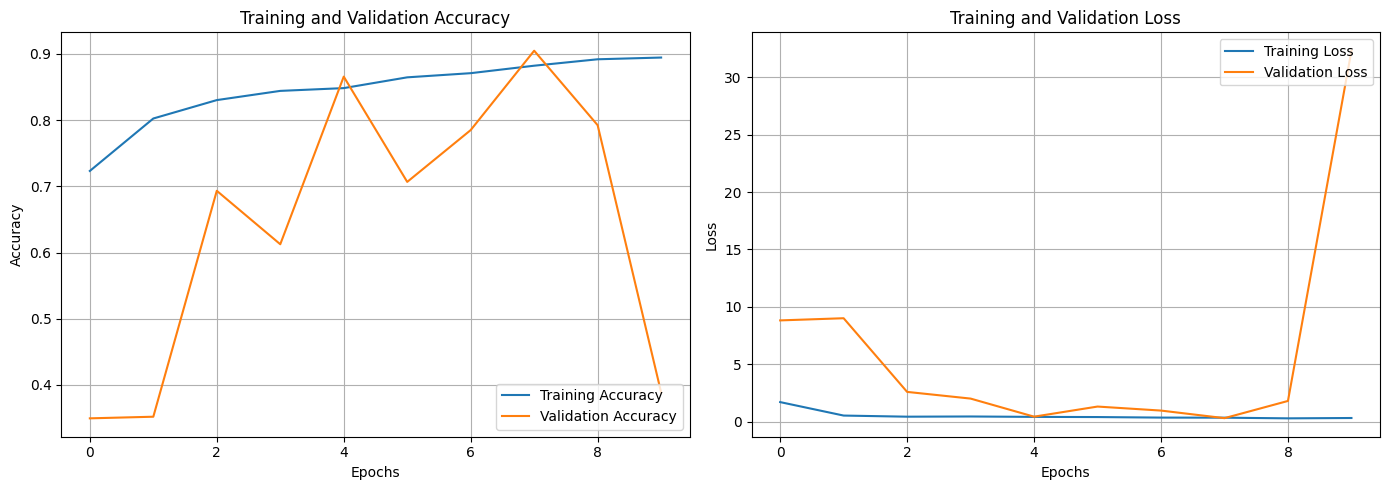

In [12]:
# Retrieve training values
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

# Plot Loss & Accuracy Curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.savefig('accuracy_graph.png')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.savefig('loss_graph.png')

plt.tight_layout()
plt.show()

## 9. Model Evaluation

Let's evaluate the performance of our best model on the test split using the confusion matrix, classification report, and direct visual evaluation.

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

# Load the best saved checkpoint
best_model = tf.keras.models.load_model('best_plant_disease_model.keras')

# Evaluate on testing subset
test_loss, test_acc = best_model.evaluate(test_generator, verbose=1)
print(f"\nTest Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.9219 - loss: 0.2366

Test Accuracy: 92.19%
Test Loss: 0.2366


In [14]:
# Retrieve predictions and compute metrics
test_generator.reset()
predictions = best_model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

# Classification Report
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv('classification_report.csv')

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step
Classification Report:
                     precision    recall  f1-score   support

Tomato_early_blight       0.76      0.97      0.85       150
     Tomato_healthy       0.99      1.00      0.99       239
 Tomato_late_blight       0.94      0.87      0.90       287
   Tomato_leaf_mold       0.99      0.85      0.92       143

           accuracy                           0.92       819
          macro avg       0.92      0.92      0.92       819
       weighted avg       0.93      0.92      0.92       819



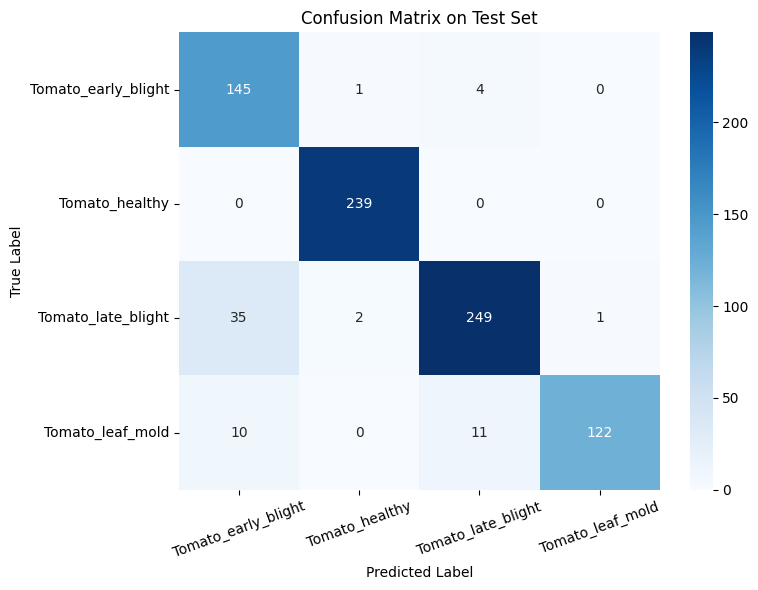

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

## 10. Sample Test Predictions

Let's display randomized sample test images alongside their ground truth and predicted labels.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 634ms/step


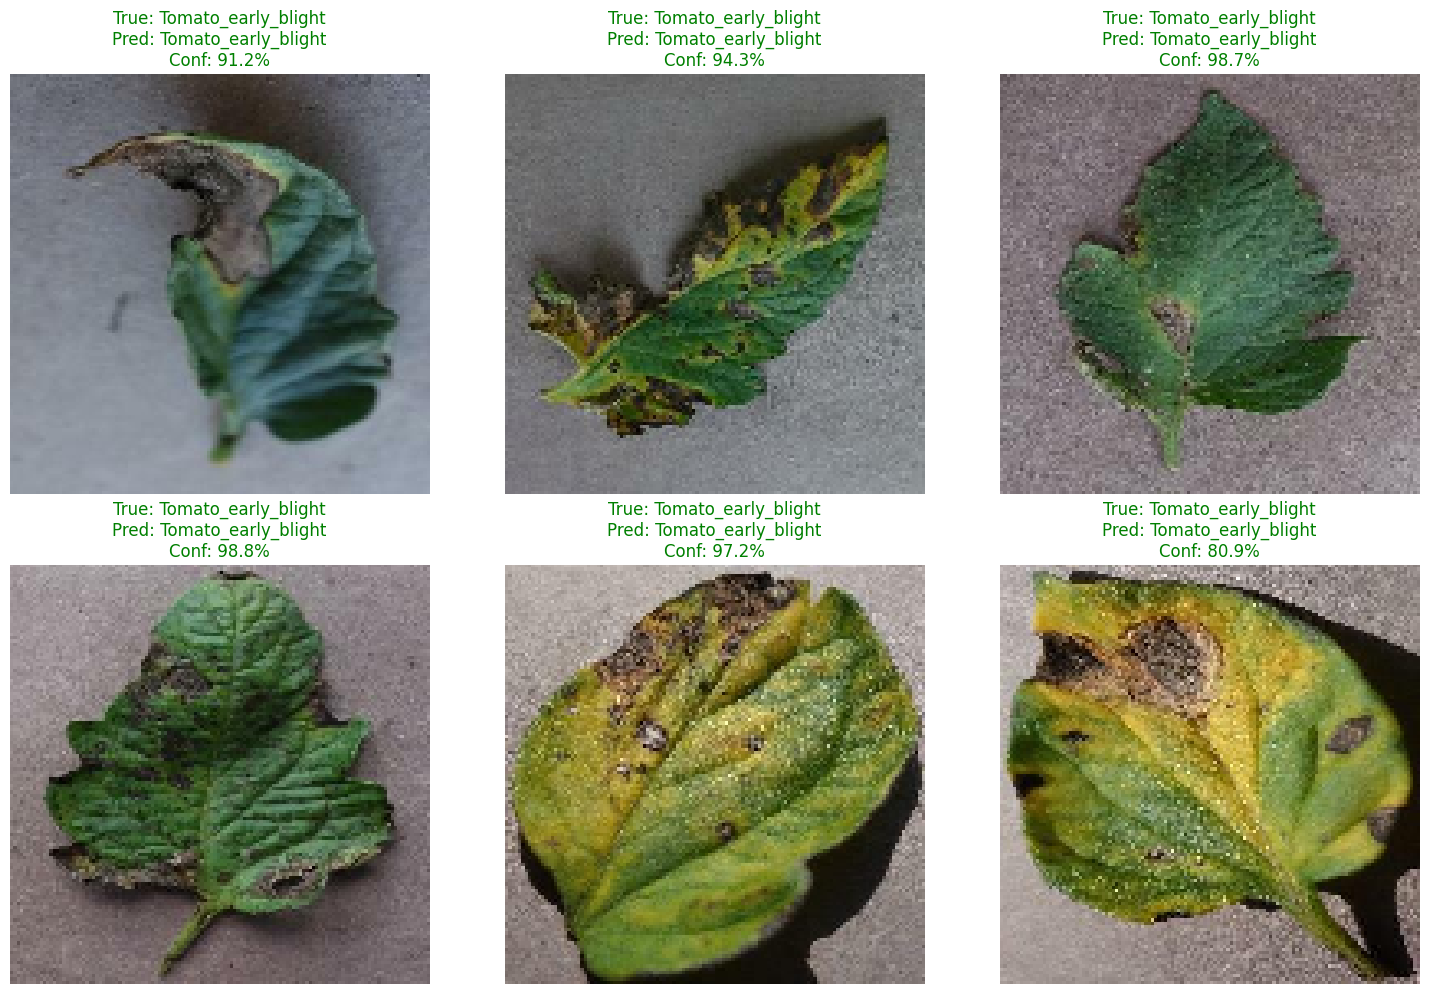

In [16]:
# Get batch samples and display
x_batch, y_batch = next(test_generator)
preds_batch = best_model.predict(x_batch)
pred_labels_batch = np.argmax(preds_batch, axis=1)

plt.figure(figsize=(15, 10))
for i in range(min(6, len(x_batch))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(x_batch[i])

    true_name = class_names[int(y_batch[i])]
    pred_name = class_names[pred_labels_batch[i]]
    confidence = preds_batch[i][pred_labels_batch[i]]

    color = 'green' if true_name == pred_name else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}\nConf: {confidence*100:.1f}%", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 11. Predict Disease from Your Own Leaf Image

You can upload any custom leaf image and see how our trained CNN model performs!

Upload your plant leaf image file (JPG, JPEG, PNG):


Saving Tomato_plant_leaves.jpg to Tomato_plant_leaves.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


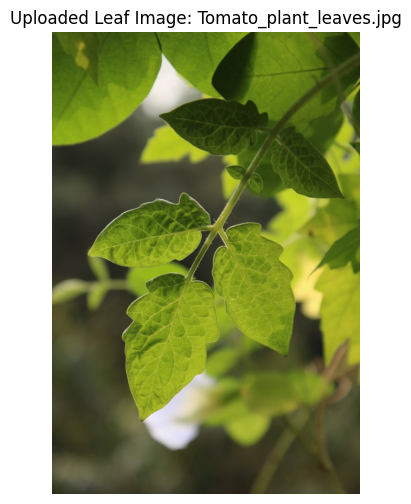


--- Prediction Results ---
Predicted Class: Tomato_late_blight (Confidence: 94.39%)

Class Distribution Scores:
 - Tomato_early_blight: 5.61%
 - Tomato_healthy: 0.00%
 - Tomato_late_blight: 94.39%
 - Tomato_leaf_mold: 0.00%

Disclaimer: This output is generated by an experimental AI model and does not represent a professional agricultural diagnosis.


In [17]:
from google.colab import files

print("Upload your plant leaf image file (JPG, JPEG, PNG):")
uploaded = files.upload()

for fn in uploaded.keys():
    # Process image
    img_path = fn
    img = Image.open(img_path).convert('RGB')
    img_resized = img.resize(IMG_SIZE)
    img_array = np.array(img_resized) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    # Predict
    raw_preds = best_model.predict(img_batch)[0]
    pred_class_idx = np.argmax(raw_preds)
    predicted_class = class_names[pred_class_idx]
    confidence = raw_preds[pred_class_idx]

    # Display
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Uploaded Leaf Image: {fn}")
    plt.axis('off')
    plt.show()

    print("\n--- Prediction Results ---")
    print(f"Predicted Class: {predicted_class} (Confidence: {confidence*100:.2f}%)")
    print("\nClass Distribution Scores:")
    for c_idx, c_name in enumerate(class_names):
        print(f" - {c_name}: {raw_preds[c_idx]*100:.2f}%")
    print("\nDisclaimer: This output is generated by an experimental AI model and does not represent a professional agricultural diagnosis.")

## 12. Save and Download Results

We package the trained model weights, class indices mapping, performance graphs, metrics files, and confusion matrices into a structured zip deliverable.

In [18]:
import zipfile

# Create final deliverables directory
deliverables_dir = '/content/deliverables'
os.makedirs(deliverables_dir, exist_ok=True)

# Copy resources
shutil.copy('best_plant_disease_model.keras', deliverables_dir)
shutil.copy('class_indices.json', deliverables_dir)
shutil.copy('accuracy_graph.png', deliverables_dir)
shutil.copy('loss_graph.png', deliverables_dir)
shutil.copy('classification_report.csv', deliverables_dir)
shutil.copy('confusion_matrix.png', deliverables_dir)

# Build README
readme_content = """# Plant Disease Detection Deliverables

This zip file contains the deliverables generated during training:
1. best_plant_disease_model.keras - Best epoch model checkpoint weights.
2. class_indices.json - Class mapping representation.
3. accuracy_graph.png / loss_graph.png - Plot records of metrics updates.
4. classification_report.csv / confusion_matrix.png - Metrics matrices.
"""

with open(os.path.join(deliverables_dir, 'README.md'), 'w') as f:
    f.write(readme_content)

# Compress into a ZIP archive
zip_path = '/content/Plant_Disease_Detection_Deliverables.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_in_dir in os.walk(deliverables_dir):
        for file in files_in_dir:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"Deliverables ZIP created at: {zip_path}")

Deliverables ZIP created at: /content/Plant_Disease_Detection_Deliverables.zip


In [19]:
from google.colab import files
print("To download your models and reports, execute this cell:")
try:
    files.download(zip_path)
except Exception as e:
    print(f"File download failed or skipped: {e}")

To download your models and reports, execute this cell:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>